# Задание 1. Palmer Penguins

Источник — [Palmer Penguins (Horst, Hill и Gorman)](https://allisonhorst.github.io/palmerpenguins/), CC0.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks")
SEED = 42

In [2]:
def inspect_data(raw, features, target="class"):
    df = raw.dropna(subset=[*features, target]).copy()
    missing_measurements = raw[features].isna().any(axis=1)
    display(pd.DataFrame({
        "исходные строки": [len(raw)],
        "исходные столбцы": [raw.shape[1]],
        "исходные признаки": [raw.shape[1] - 1],
        "выбранные признаки": [len(features)],
        "классы": [raw[target].nunique()],
        "строки с пропусками, %": [100 * raw.isna().any(axis=1).mean()],
        "строки с пропусками в выбранных измерениях": [missing_measurements.sum()],
        "строки с пропусками в выбранных измерениях, %": [100 * missing_measurements.mean()],
        "строки после очистки": [len(df)],
    }))
    display(pd.concat(
        [raw[target].value_counts().rename("до"), df[target].value_counts().rename("после")],
        axis=1,
    ).sort_index())
    display(df[features].describe().round(3))
    for label, subset in [("Вся выборка", df), *df.groupby(target, sort=True)]:
        display(subset[features].corr(method="pearson").round(3)
                .style.set_caption(f"Корреляция Пирсона · {label}"))
    return df

def pairplot(df, features, target="class"):
    classes = sorted(df[target].unique())
    graph = sns.pairplot(
        df, vars=features, hue=target, markers=["o", "s", "^", "D", "v", "P", "X"][:len(classes)],
        diag_kind="hist", diag_kws={"bins": 20, "element": "step", "fill": False},
        plot_kws={"alpha": 0.55, "s": 12, "linewidth": 0}, height=1.75,
    )
    graph.fig.set_dpi(95)
    plt.show()

,исходные строки,исходные столбцы,исходные признаки,выбранные признаки,классы,"строки с пропусками, %",строки с пропусками в выбранных измерениях,"строки с пропусками в выбранных измерениях, %",строки после очистки
0,344,8,7,4,3,3.197674,2,0.581395,342


,до,после
class,,
Adelie,152,151
Chinstrap,68,68
Gentoo,124,123


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000,342.000,342.000,342.000
mean,43.922,17.151,200.915,4201.754
std,5.460,1.975,14.062,801.955
min,32.100,13.100,172.000,2700.000
25%,39.225,15.600,190.000,3550.000
50%,44.450,17.300,197.000,4050.000
75%,48.500,18.700,213.000,4750.000
max,59.600,21.500,231.000,6300.000


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235000,0.656000,0.595000
bill_depth_mm,-0.235000,1.000000,-0.584000,-0.472000
flipper_length_mm,0.656000,-0.584000,1.000000,0.871000
body_mass_g,0.595000,-0.472000,0.871000,1.000000


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,0.391000,0.326000,0.549000
bill_depth_mm,0.391000,1.000000,0.308000,0.576000
flipper_length_mm,0.326000,0.308000,1.000000,0.468000
body_mass_g,0.549000,0.576000,0.468000,1.000000


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,0.654000,0.472000,0.514000
bill_depth_mm,0.654000,1.000000,0.580000,0.604000
flipper_length_mm,0.472000,0.580000,1.000000,0.642000
body_mass_g,0.514000,0.604000,0.642000,1.000000


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,0.643000,0.661000,0.669000
bill_depth_mm,0.643000,1.000000,0.707000,0.719000
flipper_length_mm,0.661000,0.707000,1.000000,0.703000
body_mass_g,0.669000,0.719000,0.703000,1.000000


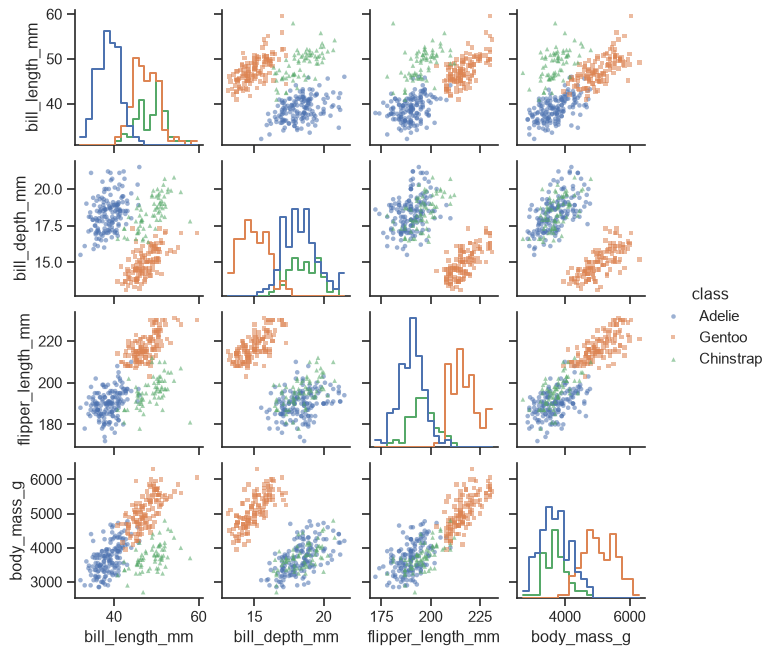

In [3]:
from urllib.request import urlopen

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import auc, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

url = (
    "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/"
    "156daa4301838d9fdcc5b018b29b9149bf975552/inst/extdata/penguins.csv"
)
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
with urlopen(url, timeout=30) as csv:
    raw = pd.read_csv(csv).rename(columns={"species": "class"})
df = inspect_data(raw, features)
pairplot(df, features)

## LDA на шести парах признаков

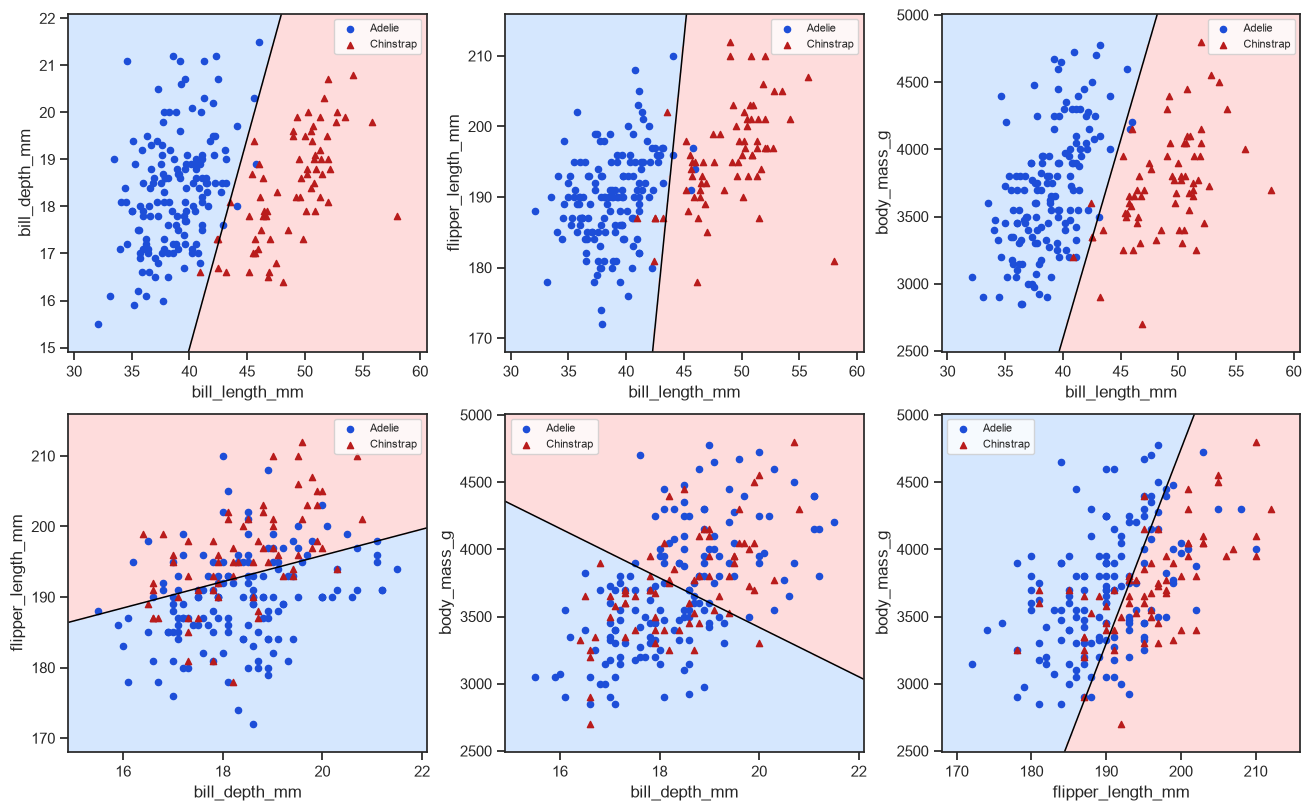

In [4]:
binary = df.loc[df["class"].isin(["Adelie", "Chinstrap"])].copy()
labels = binary["class"].eq("Chinstrap").astype(int)
pairs = list(itertools.combinations(features, 2))

def draw_boundary(ax, model, axes):
    points = binary[list(axes)].to_numpy()
    span = np.ptp(points, axis=0) * 0.10
    x, y = [np.linspace(lo, hi, 140) for lo, hi in
            zip(points.min(axis=0) - span, points.max(axis=0) + span)]
    xx, yy = np.meshgrid(x, y)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    if hasattr(model, "decision_function"):
        values = model.decision_function(grid)
    else:
        values = model.predict_proba(grid)[:, 1] - 0.5
    scores = values.reshape(xx.shape)
    ax.contourf(xx, yy, scores >= 0, levels=[-0.5, 0.5, 1.5],
                colors=["#bfdbfe", "#fecaca"], alpha=0.65)
    ax.contour(xx, yy, scores, levels=[0], colors="black", linewidths=1.1)
    for label, name, marker, color in [(0, "Adelie", "o", "#1d4ed8"),
                                       (1, "Chinstrap", "^", "#b91c1c")]:
        ax.scatter(*points[labels == label].T, label=name, marker=marker, c=color, s=20)
    ax.set(xlabel=axes[0], ylabel=axes[1])
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
for ax, pair in zip(axes.flat, pairs):
    model = LinearDiscriminantAnalysis(priors=[0.5, 0.5]).fit(binary[list(pair)].to_numpy(), labels)
    draw_boundary(ax, model, pair)
plt.show()

## Граница LDA и линейная регрессия

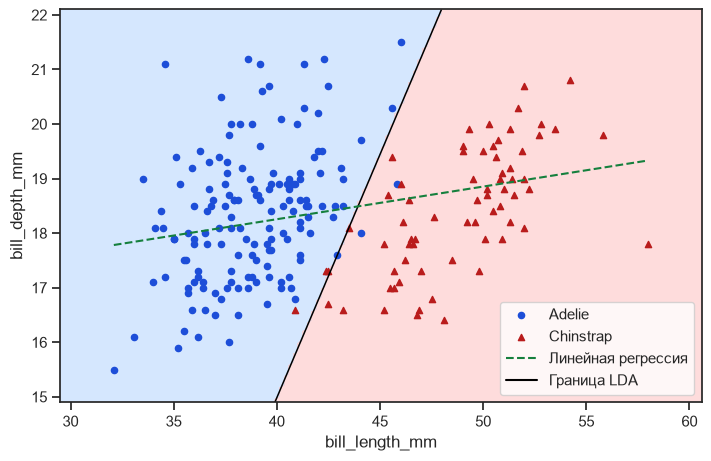

In [5]:
selected = ["bill_length_mm", "bill_depth_mm"]
points = binary[selected].to_numpy()
lda = LinearDiscriminantAnalysis(priors=[0.5, 0.5]).fit(points, labels)
regression = LinearRegression().fit(points[:, :1], points[:, 1])

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
draw_boundary(ax, lda, selected)
x = np.linspace(points[:, 0].min(), points[:, 0].max(), 150)
ax.plot(x, regression.predict(x[:, None]), "--", c="#15803d", label="Линейная регрессия")
ax.plot([], [], c="black", label="Граница LDA")
ax.legend()
plt.show()

## Границы классификаторов, матрицы ошибок и ROC

,Прогноз: Adelie,Прогноз: Chinstrap
Истина: Adelie,45,1
Истина: Chinstrap,0,20


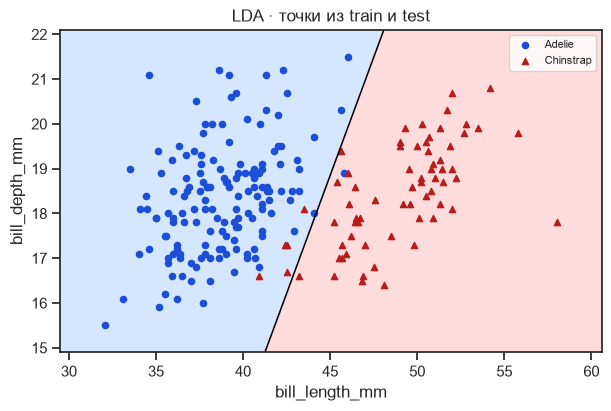

,Прогноз: Adelie,Прогноз: Chinstrap
Истина: Adelie,45,1
Истина: Chinstrap,1,19


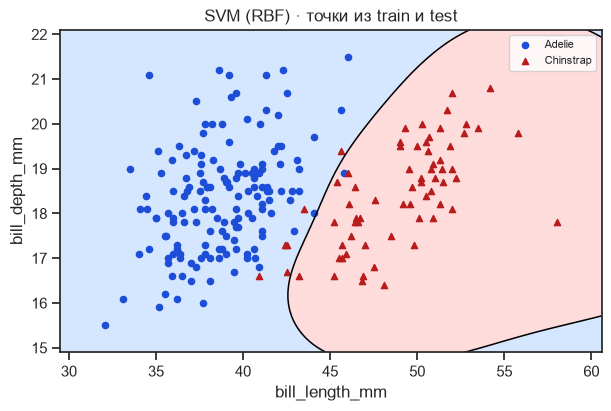

,Прогноз: Adelie,Прогноз: Chinstrap
Истина: Adelie,45,1
Истина: Chinstrap,1,19


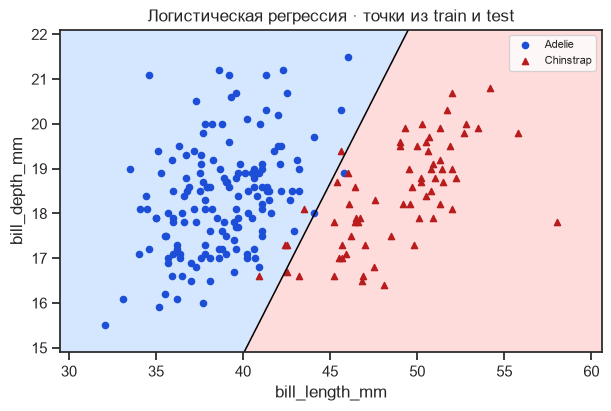

,Прогноз: Adelie,Прогноз: Chinstrap
Истина: Adelie,45,1
Истина: Chinstrap,1,19


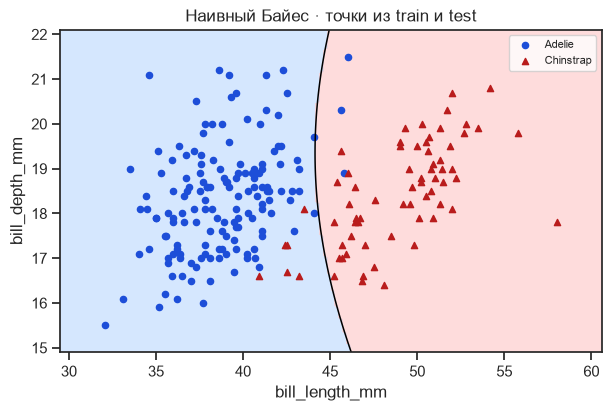

,sensitivity,specificity,precision,recall,AUROC
модель,,,,,
LDA,1.00,0.978,0.952,1.00,0.998
SVM (RBF),0.95,0.978,0.950,0.95,0.998
Логистическая регрессия,0.95,0.978,0.950,0.95,0.999
Наивный Байес,0.95,0.978,0.950,0.95,0.990


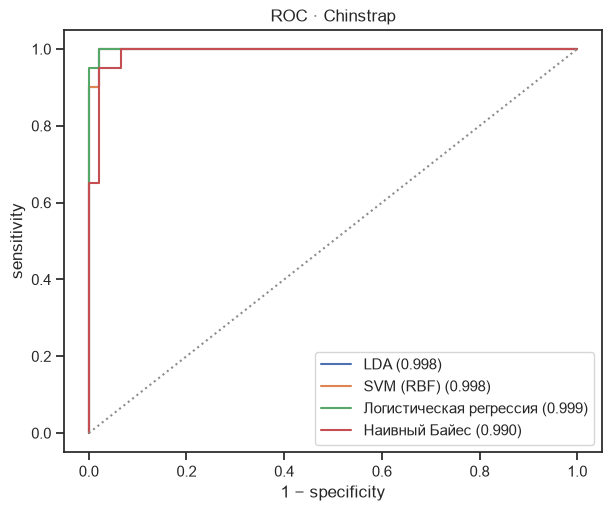

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    points, labels, test_size=0.30, stratify=labels, random_state=SEED,
)
models = {
    "LDA": LinearDiscriminantAnalysis(),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Логистическая регрессия": make_pipeline(StandardScaler(), LogisticRegression()),
    "Наивный Байес": GaussianNB(),
}

fig, roc_ax = plt.subplots(figsize=(6, 5), layout="constrained")
plt.close(fig)
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    boundary_fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    draw_boundary(ax, model, selected)
    ax.set_title(name + " · точки из train и test")
    matrix = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    display(pd.DataFrame(
        matrix, index=["Истина: Adelie", "Истина: Chinstrap"],
        columns=["Прогноз: Adelie", "Прогноз: Chinstrap"],
    ).style.set_caption(name))
    scores = (model.decision_function(X_test) if hasattr(model, "decision_function")
              else model.predict_proba(X_test)[:, 1])
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)
    results.append({
        "модель": name, "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn), "AUROC": roc_auc,
    })
    roc_ax.plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
    plt.show()
display(pd.DataFrame(results).set_index("модель").round(3))
roc_ax.plot([0, 1], [0, 1], ":", color="0.55")
roc_ax.set(xlabel="1 − specificity", ylabel="sensitivity", title="ROC · Chinstrap")
roc_ax.legend()
display(fig)
plt.close(fig)